# Compute-optimal hyperparameter trends (Figures 5-6)

Value of each hyperparameter (`trends_searched`) and derived quantity (`trends_derived`) on the compute frontier of
each metric, with a power-law fit $y = c\,C^{\gamma}$ in log-log space. Frontier and fit use grid points up to
$10^{16}$ FLOPs; the budgets up to $10^{17}$ FLOPs are held out (open markers, shaded). Exponents are also written
as CSV and LaTeX.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, NullLocator

from scaling.utils import fit_linear_model


In [2]:
base_figure_path = Path.cwd() / "figures"
base_figure_path.mkdir(parents=True, exist_ok=True)
base_output_path = Path.cwd() / "tables"
base_output_path.mkdir(parents=True, exist_ok=True)


## Data loading


In [3]:
df = pd.read_csv("../data/nanotabpfn_model_tabiclv1_prior.csv", index_col=[0, 1])

FLOP_VALUES = np.array([
    1.00000000e+11, 1.77827941e+11, 3.16227766e+11, 5.62341325e+11,
    1.00000000e+12, 1.77827941e+12, 3.16227766e+12, 5.62341325e+12,
    1.00000000e+13, 1.77827941e+13, 3.16227766e+13, 5.62341325e+13,
    1.00000000e+14, 1.77827941e+14, 3.16227766e+14, 5.62341325e+14,
    1.00000000e+15, 1.77827941e+15, 3.16227766e+15, 5.62341325e+15,
    1.00000000e+16, 1.77827941e+16, 3.16227766e+16, 5.62341325e+16,
    1.00000000e+17, 1.77827941e+17, 3.16227766e+17, 5.62341325e+17,
    1.00000000e+18,
])
FILTER_FLOPS = 1.00000000e+17 * 1.05        # largest grid point kept at all
FIT_FLOPS_MAX = 1.00000000e+16 * 1.05       # frontier + fit use grid points below this, larger ones are held out

df = df[df['total_flops_rounded'] < FILTER_FLOPS]

# Add additional columns to analyse
df['prior_max_cells'] = df['config/max_features'] * df['config/num_datapoints_max']
df['embedding_layer_ratio'] = df['config/model_config.embedding_size'] / df['config/model_config.num_layers']
df['prior_datapoint_feature_ratio'] = df['config/num_datapoints_max'] / df['config/max_features']

flops_column = 'total_flops_rounded'
print(df.shape)


(60214, 106)


In [4]:
def get_pareto_frontier(
        df: pd.DataFrame,
        x_name="flops",
        y_name="Validation Loss",
        minimization=True,
) -> pd.DataFrame:
    """ Function to compute Pareto over FLOPs.
    """
    # NOTE: strict assumption here that x_name is maximized and y_name is minimized
    df_copy = df.copy()
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    df_sorted = df_copy.sort_values(by=[x_name, y_name], ascending=[True, True])
    df_sorted = df_sorted.drop_duplicates(subset=[x_name], keep="first")
    pareto_points = []
    min_loss_so_far = float('inf')
    for _, row in df_sorted.iterrows():
        if row[y_name] < min_loss_so_far:
            pareto_points.append(row)
            min_loss_so_far = row[y_name]

    df_copy = pd.DataFrame(pareto_points)
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    return df_copy


def get_optimal_values(df, x_name, y_name, minimization=True):
    """Best run at every FLOP level (no frontier condition); used for the held-out budgets."""
    if len(df) == 0:
        return df
    idx = df.groupby(x_name)[y_name].idxmin() if minimization else df.groupby(x_name)[y_name].idxmax()
    return df.loc[idx].sort_values(x_name)


## Figure definition

`METRICS` fixes order, colour and label per metric; `SEARCHED` and `DERIVED` map a column to its label, y-scale and
whether a power law is fitted.

In [5]:
# ---- paper sizing: figure width = text width of the paper, fonts in true points ---------------------------
FIG_WIDTH = 6.75      # inch; \textwidth of a NeurIPS/ICML-style single-column layout
ROW_HEIGHT = 1.15     # inch per panel row
FONT = 8              # pt; base font size of labels
FIT_COLOR = "0.25"

plt.rcParams.update({
    "font.size": FONT, "axes.labelsize": FONT, "axes.titlesize": FONT + 0.5,
    "xtick.labelsize": FONT - 1, "ytick.labelsize": FONT - 1, "legend.fontsize": FONT - 1,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.minor.size": 1.5, "ytick.minor.size": 1.5,
})

METRICS = {
    'real_data/nll':       {"color": "#d1121f", "label": "NLL\n(real data)",         "maximize": False},
    'real_data/roc_auc':   {"color": "#e07b00", "label": "ROC AUC\n(real data)",     "maximize": True},
    'val/val_loss':        {"color": "#2a78d6", "label": "Val. loss\n(prior)",        "maximize": False},
    'val/small/val_loss':  {"color": "#1baf7a", "label": "Val. loss\n(small prior)",  "maximize": False},
    'val/medium/val_loss': {"color": "#4a3aa7", "label": "Val. loss\n(medium prior)", "maximize": False},
}

# column of df -> (row label, y scale, fit a power law?)
SEARCHED = {
    'config/lr':                               ("Learning rate",             "log",    True),
    'config/weight_decay':                     ("Weight decay",              "symlog", False),
    'config/effective_batch_size':             ("Batch size",                "log",    True),
    'config/model_config.embedding_size':      ("Embedding size",            "log",    True),
    'config/model_config.num_layers':          ("Layers",                    "log",    True),
    'config/model_config.num_attention_heads': ("Attention heads",           "log",    True),
    'config/max_features':                     ("Max. features",             "log",    True),
    'config/num_datapoints_max':               ("Max. datapoints",           "log",    True),
}
DERIVED = {
    'parameters':                    ("Parameters",               "log", True),
    'total_cells':                   ("Training cells",           "log", True),
    'prior_max_cells':               ("Max. cells\nper table",    "log", True),
    'embedding_layer_ratio':         ("Embedding size\n/ layers", "log", True),
    'prior_datapoint_feature_ratio': ("Datapoints\n/ features",   "log", True),
}
MAX_DISCRETE = 9   # quantities with at most this many distinct values are treated as a searched grid


In [6]:
def nice(v):
    """Tick label for a searched value: plain integers, 10^k for powers of ten, m e k otherwise."""
    if v == 0:
        return "0"
    if v >= 1 and (v < 1000 or not float(v).is_integer()):
        return f"{v:g}"
    e = int(np.floor(np.log10(v)))
    m = v / 10 ** e
    return f"$10^{{{e}}}$" if np.isclose(m, 1) else (f"{v:g}" if v >= 1 else f"{m:.1f}e{e}")


def style_y(axes_row, scale, values, shown):
    """y axis of one row (axes share y). `values` = every value in the sweep, `shown` = values on the frontiers."""
    ax = axes_row[0]
    values = np.sort(np.asarray(values, dtype=float))
    shown = np.asarray(shown, dtype=float)
    pos = values[values > 0]
    lo, hi = shown[shown > 0].min(), shown.max()
    discrete = len(values) <= MAX_DISCRETE

    if scale == "symlog":
        lin = pos.min()
        ax.set_yscale("symlog", linthresh=lin, linscale=0.4)
        ax.set_ylim(-lin * 0.3, hi * 3)
        ax.yaxis.set_major_locator(FixedLocator(values))
        ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: nice(v)))
        return

    ax.set_yscale("log")
    ax.set_ylim(lo / 1.6, hi * 1.6)
    in_range = values[(values >= lo / 1.6) & (values <= hi * 1.6)]
    if discrete:
        for a in axes_row:                       # light lines mark the searched grid
            for v in in_range:
                a.axhline(v, color="0.88", lw=0.5, zorder=0)
        keep = [in_range[0]]                     # drop tick labels that would overlap in log space
        for v in in_range[1:]:
            if np.log10(v / keep[-1]) > 0.15:
                keep.append(v)
        ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_locator(FixedLocator(keep))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: nice(v)))
    else:
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=4))
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs="auto", numticks=10))
        ax.yaxis.set_minor_formatter(NullFormatter())


def trend_grid(df, quantities, metrics):
    """One column per metric, one row per quantity: frontier value vs. compute, plus power-law fit and exponent."""
    nrows, ncols = len(quantities), len(metrics)
    fig, axes = plt.subplots(nrows, ncols, figsize=(FIG_WIDTH, ROW_HEIGHT * nrows + 0.5),
                             sharex=True, sharey="row", layout="constrained", squeeze=False)
    fit_df = df[df[flops_column] < FIT_FLOPS_MAX]
    held_df = df[df[flops_column] > FIT_FLOPS_MAX]
    frontiers = {m: get_pareto_frontier(fit_df, flops_column, m, minimization=not METRICS[m]["maximize"])
                 for m in metrics}
    held_out = {m: get_optimal_values(held_df, flops_column, m, minimization=not METRICS[m]["maximize"])
                for m in metrics}
    exponents = []

    for col, m in enumerate(metrics):
        pareto, held, ms = frontiers[m], held_out[m], METRICS[m]
        axes[0, col].set_title(ms["label"], color=ms["color"], fontweight="bold")
        for row, (q, (label, scale, fit)) in enumerate(quantities.items()):
            ax = axes[row, col]
            x, y = pareto[flops_column].to_numpy(), pareto[q].to_numpy()
            ax.plot(x, y, color=ms["color"], lw=1.0, marker="o", ms=2.2, mew=0, alpha=0.95, zorder=3)
            if len(held):
                ax.plot(held[flops_column], held[q], color=ms["color"], lw=0, marker="o", ms=2.8,
                        mfc="white", mew=0.8, zorder=3)
            ax.axvspan(FIT_FLOPS_MAX, FILTER_FLOPS * 1.5, color="0.93", lw=0, zorder=0)
            ax.set_xscale("log")
            if fit:
                slope, intercept, r_value, p_value, std_err = fit_linear_model(np.log(x), np.log(y))
                ax.plot(FLOP_VALUES, np.exp(intercept + slope * np.log(FLOP_VALUES)),
                        color=FIT_COLOR, lw=0.8, ls="--", zorder=2)
                top = slope >= 0   # rising trends start low-left, falling ones high-left: keep the label clear
                ax.text(0.04, 0.93 if top else 0.07, rf"$\gamma={slope:.2f}$" + "\n" + rf"$R^2={r_value ** 2:.2f}$",
                        transform=ax.transAxes, linespacing=1.1,
                        ha="left", va="top" if top else "bottom", fontsize=FONT - 1.5, color=FIT_COLOR,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
                exponents.append({"quantity": q, "label": label.replace("\n", " "), "metric": m,
                                  "exponent": slope, "std_err": std_err, "r2": r_value ** 2})
            if col == 0:
                shown = np.concatenate([frontiers[mm][q].to_numpy() for mm in metrics]
                                       + [held_out[mm][q].to_numpy() for mm in metrics if len(held_out[mm])])
                style_y(axes[row], scale, df[q].unique(), shown)
                ax.set_ylabel(label)

    axes[0, 0].set_xlim(FLOP_VALUES[0] / 1.5, FILTER_FLOPS * 1.5)
    for ax in axes[-1]:
        ax.xaxis.set_major_locator(FixedLocator([1e11, 1e13, 1e15, 1e17]))
        ax.xaxis.set_minor_locator(FixedLocator([1e12, 1e14, 1e16]))
        ax.xaxis.set_minor_formatter(NullFormatter())
    fig.supxlabel("Compute $C$ (FLOPs)", fontsize=FONT + 0.5)
    handles = [Line2D([], [], color="0.4", lw=1.0, marker="o", ms=2.5, mew=0,
                      label=r"compute frontier ($\leq 10^{16}$ FLOPs)"),
               Line2D([], [], color=FIT_COLOR, lw=0.8, ls="--", label=r"power-law fit $y \propto C^{\gamma}$"),
               Line2D([], [], color="0.4", lw=0, marker="o", ms=3, mfc="white", mew=0.8,
                      label=r"held out: best run per budget ($> 10^{16}$ FLOPs, shaded)")]
    fig.legend(handles=handles, loc="outside upper center", ncol=3, frameon=False, borderaxespad=0.2)
    return fig, pd.DataFrame(exponents)


def save(fig, name):
    fig.savefig(base_figure_path / f"{name}.pdf")


## Figure 5: searched hyperparameters


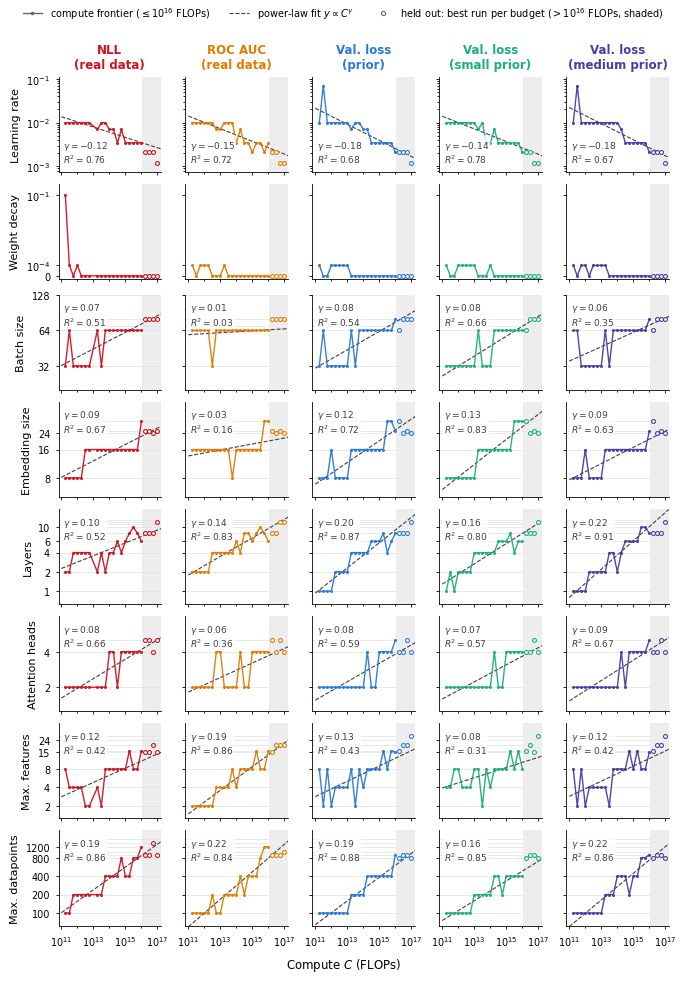

In [7]:
fig, exponents_searched = trend_grid(df, SEARCHED, list(METRICS))
save(fig, "trends_searched")
plt.show()


## Figure 6: derived quantities


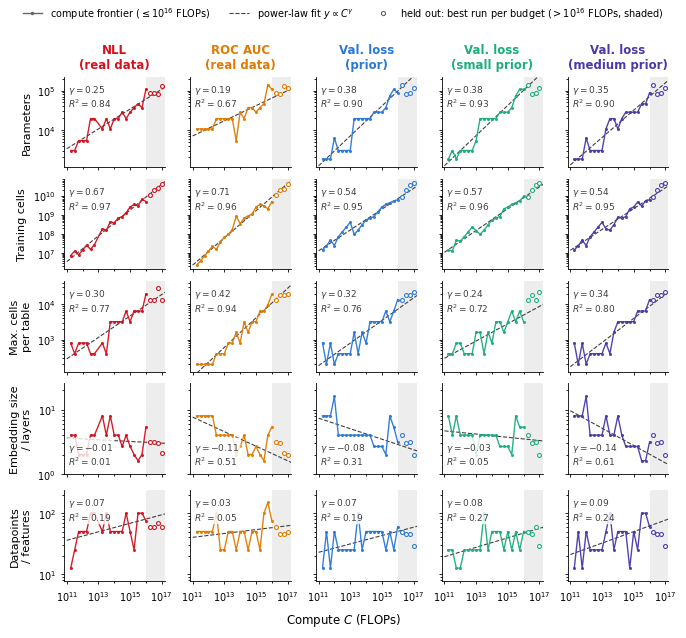

In [8]:
fig, exponents_derived = trend_grid(df, DERIVED, list(METRICS))
save(fig, "trends_derived")
plt.show()


## Exponent table

In [9]:
exponents = pd.concat([exponents_searched.assign(group="searched"), exponents_derived.assign(group="derived")],
                      ignore_index=True)
exponents.to_csv(base_output_path / "hyperparameter_trend_exponents.csv", index=False)

table = exponents.pivot(index=["group", "label"], columns="metric", values="exponent")
table = table.loc[[("searched", lbl.replace("\n", " ")) for _, (lbl, _, fit) in SEARCHED.items() if fit]
                  + [("derived", lbl.replace("\n", " ")) for _, (lbl, _, fit) in DERIVED.items() if fit]]
table = table[list(METRICS)]
table.columns = [METRICS[m]["label"].replace("\n", " ") for m in table.columns]

lines = [
    "% Exponents gamma of the power-law fits y = c * C^gamma to the compute-optimal value of each quantity.",
    "% Generated by playground/paper_hyperparameter_trends.ipynb; see figures/trends_*.pdf.",
    r"\begin{table}[t]", r"  \centering", r"  \small",
    r"  \begin{tabular}{l" + "r" * len(table.columns) + "}", r"    \hline",
    "    Quantity & " + " & ".join(table.columns) + r" \\", r"    \hline",
]
for group, block in table.groupby(level=0, sort=False):
    if group == "derived":
        lines += [r"    \hline",
                  r"    \multicolumn{%d}{l}{\emph{Derived quantities (not searched directly)}} \\" % (len(table.columns) + 1),
                  r"    \hline"]
    for (_, label), row in block.iterrows():
        lines.append("    " + label + " & " + " & ".join(f"{v:.2f}" for v in row) + r" \\")
lines += [
    r"    \hline", r"  \end{tabular}",
    r"  \caption{Exponents $\gamma$ of the power-law fits $y = c\,C^{\gamma}$ to the compute-optimal value of each "
    r"quantity, one fit per metric frontier, fitted on budgets up to $10^{16}$ FLOPs. Weight decay is not fitted.}",
    r"  \label{tab:trend_exponents}", r"\end{table}",
]
(base_output_path / "hyperparameter_trend_exponents.tex").write_text("\n".join(lines) + "\n")
table.round(2)


NLL (real data)  ROC AUC (real data)  \
group    label                                                           
searched Learning rate                      -0.12                -0.15   
         Batch size                          0.07                 0.01   
         Embedding size                      0.09                 0.03   
         Layers                              0.10                 0.14   
         Attention heads                     0.08                 0.06   
         Max. features                       0.12                 0.19   
         Max. datapoints                     0.19                 0.22   
derived  Parameters                          0.25                 0.19   
         Training cells                      0.67                 0.71   
         Max. cells per table                0.30                 0.42   
         Embedding size / layers            -0.01                -0.11   
         Datapoints / features               0.07                 0.03   

                                  Val. loss (prior)  Val. loss (small prior)  \
group    label                                                                 
searched Learning rate                        -0.18                    -0.14   
         Batch size                            0.08                     0.08   
         Embedding size                        0.12                     0.13   
         Layers                                0.20                     0.16   
         Attention heads                       0.08                     0.07   
         Max. features                         0.13                     0.08   
         Max. datapoints                       0.19                     0.16   
derived  Parameters                            0.38                     0.38   
         Training cells                        0.54                     0.57   
         Max. cells per table                  0.32                     0.24   
         Embedding size / layers              -0.08                    -0.03   
         Datapoints / features                 0.07                     0.08   

                                  Val. loss (medium prior)  
group    label                                              
searched Learning rate                               -0.18  
         Batch size                                   0.06  
         Embedding size                               0.09  
         Layers                                       0.22  
         Attention heads                              0.09  
         Max. features                                0.12  
         Max. datapoints                              0.22  
derived  Parameters                                   0.35  
         Training cells                               0.54  
         Max. cells per table                         0.34  
         Embedding size / layers                     -0.14  
         Datapoints / features                        0.09